In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("Global_cyber_tread.csv")
# change the columns name for the simplycity
df.columns = ["country","year","attack_type","industry","loss_musd","user_affected","source","vulnerability","defense","resolution_hrs"]

print(df.shape) # it gives the number of rows and columns in the data
df.info() #its gives the inforamation about the rach columns data types 
print(df.isna().sum()) # they are count the null value in each columns..
print(df.duplicated().sum())  # they are count the duplicate rows 
df.describe()

(3000, 10)
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country         3000 non-null   str    
 1   year            3000 non-null   int64  
 2   attack_type     3000 non-null   str    
 3   industry        3000 non-null   str    
 4   loss_musd       3000 non-null   float64
 5   user_affected   3000 non-null   int64  
 6   source          3000 non-null   str    
 7   vulnerability   3000 non-null   str    
 8   defense         3000 non-null   str    
 9   resolution_hrs  3000 non-null   int64  
dtypes: float64(1), int64(3), str(6)
memory usage: 401.8 KB
country           0
year              0
attack_type       0
industry          0
loss_musd         0
user_affected     0
source            0
vulnerability     0
defense           0
resolution_hrs    0
dtype: int64
0


,year,loss_musd,user_affected,resolution_hrs
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,2019.570333,50.492970,504684.136333,36.476000
std,2.857932,28.791415,289944.084972,20.570768
min,2015.000000,0.500000,424.000000,1.000000
25%,2017.000000,25.757500,255805.250000,19.000000
50%,2020.000000,50.795000,504513.000000,37.000000
75%,2022.000000,75.630000,758088.500000,55.000000
max,2024.000000,99.990000,999635.000000,72.000000


In [2]:
print(df["year"].mean().round(0),"to",df["year"].max().round(0))
df

2020.0 to 2024


,country,year,attack_type,industry,loss_musd,user_affected,source,vulnerability,defense,resolution_hrs
0,China,2019,Phishing,Education,80.53,773169,Hacker Group,Unpatched Software,VPN,63
1,China,2019,Ransomware,Retail,62.19,295961,Hacker Group,Unpatched Software,Firewall,71
2,India,2017,Man-in-the-Middle,IT,38.65,605895,Hacker Group,Weak Passwords,VPN,20
3,UK,2024,Ransomware,Telecommunications,41.44,659320,Nation-state,Social Engineering,AI-based Detection,7
4,Germany,2018,Man-in-the-Middle,IT,74.41,810682,Insider,Social Engineering,VPN,68
...,...,...,...,...,...,...,...,...,...,...
2995,UK,2021,Ransomware,Government,51.42,190694,Unknown,Social Engineering,Firewall,52
2996,Brazil,2023,SQL Injection,Telecommunications,30.28,892843,Hacker Group,Zero-day,VPN,26
2997,Brazil,2017,SQL Injection,IT,32.97,734737,Nation-state,Weak Passwords,AI-based Detection,30
2998,UK,2022,SQL Injection,IT,32.17,379954,Insider,Unpatched Software,Firewall,9


In [3]:
for c in ["country","attack_type","industry","source","vulnerability","defense"]:
    print(f"\n{c} ({df[c].nunique()} unique):")
    print(df[c].value_counts())


country (10 unique):
country
UK           321
Brazil       310
India        308
France       305
Japan        305
Australia    297
Russia       295
Germany      291
USA          287
China        281
Name: count, dtype: int64

attack_type (6 unique):
attack_type
DDoS                 531
Phishing             529
SQL Injection        503
Ransomware           493
Malware              485
Man-in-the-Middle    459
Name: count, dtype: int64

industry (7 unique):
industry
IT                    478
Banking               445
Healthcare            429
Retail                423
Education             419
Telecommunications    403
Government            403
Name: count, dtype: int64

source (4 unique):
source
Nation-state    794
Unknown         768
Insider         752
Hacker Group    686
Name: count, dtype: int64

vulnerability (4 unique):
vulnerability
Zero-day              785
Social Engineering    747
Unpatched Software    738
Weak Passwords        730
Name: count, dtype: int64

defense (5 unique

In [4]:
# df
print(df[["loss_musd","user_affected","resolution_hrs"]].describe().round(2))

       loss_musd  user_affected  resolution_hrs
count    3000.00        3000.00         3000.00
mean       50.49      504684.14           36.48
std        28.79      289944.08           20.57
min         0.50         424.00            1.00
25%        25.76      255805.25           19.00
50%        50.80      504513.00           37.00
75%        75.63      758088.50           55.00
max        99.99      999635.00           72.00


In [5]:
df.groupby("year").agg(incidents  = ("country","size"),
                       total_loss = ("loss_musd" , "sum"),
                       avg_loss = ("loss_musd" , "mean")).round(1)
                       

,incidents,total_loss,avg_loss
year,,,
2015,277,14510.2,52.4
2016,285,13947.3,48.9
2017,319,16261.7,51.0
2018,310,14720.5,47.5
2019,263,13134.7,49.9
2020,315,15768.0,50.1
2021,299,15873.4,53.1
2022,318,15870.9,49.9
2023,315,15958.1,50.7


In [6]:
df.groupby("attack_type").agg(incidents = ("year","size"),
                              avg_loss = ("loss_musd" , "mean"),
                              avg_hours = ("resolution_hrs" , "mean")).round(1).sort_values("avg_loss" , ascending = False)
                              

,incidents,avg_loss,avg_hours
attack_type,,,
DDoS,531,52.0,35.7
Man-in-the-Middle,459,51.3,36.9
Phishing,529,50.5,35.9
SQL Injection,503,50.0,36.9
Ransomware,493,49.7,36.5
Malware,485,49.4,37.1


In [7]:
df.groupby("defense")["resolution_hrs"].agg(["mean","median"])

,mean,median
defense,,
AI-based Detection,36.612350,36.0
Antivirus,36.573248,36.0
Encryption,36.589527,37.0
Firewall,35.714530,34.0
VPN,36.864379,37.5


In [8]:
sns.set_theme(style="whitegrid" , font_scale = 1.1)

yearly = df.groupby("year").agg(incidents = ("country","size"),
                                total_loss = ("loss_musd" , "sum")).reset_index()
yearly

,year,incidents,total_loss
0,2015,277,14510.21
1,2016,285,13947.26
2,2017,319,16261.68
3,2018,310,14720.48
4,2019,263,13134.69
5,2020,315,15767.95
6,2021,299,15873.41
7,2022,318,15870.86
8,2023,315,15958.08
9,2024,299,15434.29


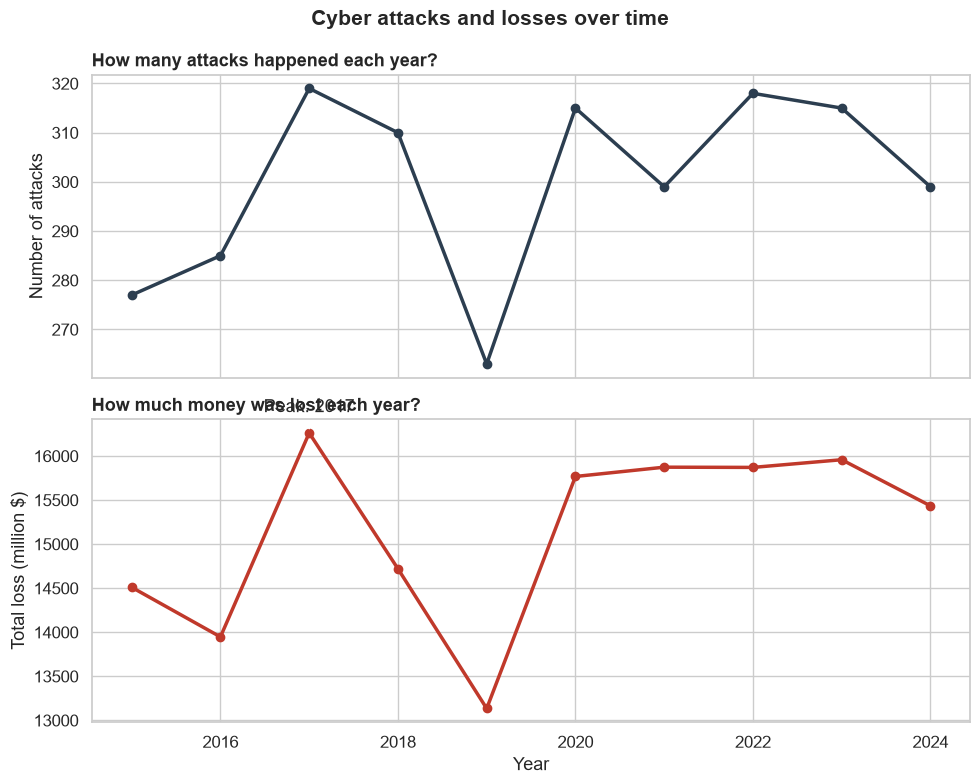

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10,8), sharex=True)

axes[0].plot(yearly["year"], yearly["incidents"], marker="o", color="#2c3e50", lw=2.5)
axes[0].set_ylabel("Number of attacks")
axes[0].set_title("How many attacks happened each year?", loc="left", weight="bold")

axes[1].plot(yearly["year"], yearly["total_loss"], marker="o", color="#c0392b", lw=2.5)
axes[1].set_ylabel("Total loss (million $)")
axes[1].set_xlabel("Year")
axes[1].set_title("How much money was lost each year?", loc="left", weight="bold")

peak = yearly.loc[yearly["total_loss"].idxmax()]
axes[1].annotate(f"Peak: {peak['year']:.0f}", (peak["year"], peak["total_loss"]),
                 xytext=(0,15), textcoords="offset points", ha="center",
                 arrowprops=dict(arrowstyle="->"))

fig.suptitle("Cyber attacks and losses over time", fontsize=15, weight="bold")
plt.tight_layout()
plt.savefig("fig1_trend.png", dpi=300, bbox_inches="tight")
plt.show()


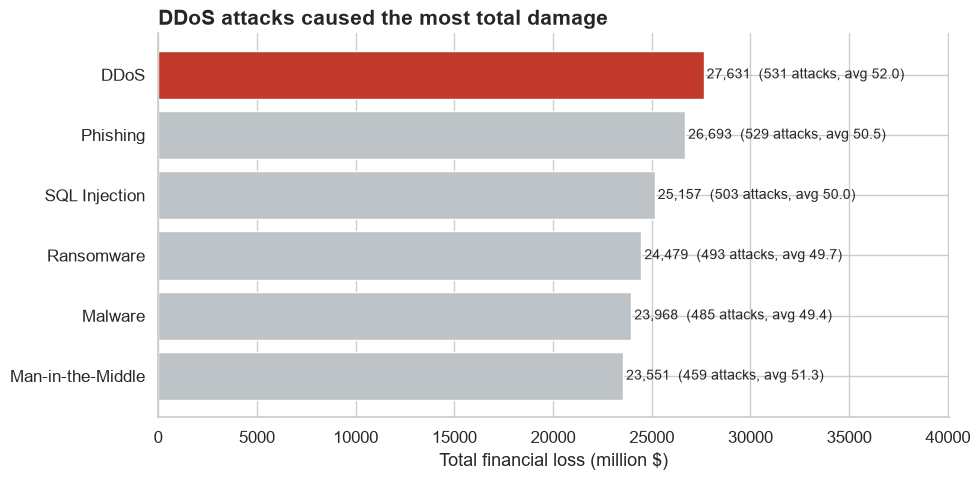

,attack_type,incidents,total_loss,avg_loss
0,Man-in-the-Middle,459,23550.87,51.309085
1,Malware,485,23967.95,49.418454
2,Ransomware,493,24479.32,49.653793
3,SQL Injection,503,25156.56,50.013042
4,Phishing,529,26693.29,50.459905
5,DDoS,531,27630.92,52.035631


In [10]:
attack = (df.groupby("attack_type")
          .agg(incidents = ("year","size"),
               total_loss=("loss_musd","sum"),
               avg_loss=("loss_musd","mean"))
          .sort_values("total_loss")
          .reset_index())

colors = ["#bdc3c7"] * (len(attack) - 1) + ["#c0392b"] 

fig, ax = plt.subplots(figsize=(10,5))
bars = ax.barh(attack["attack_type"],attack["total_loss"],color = colors)

for bar, inc, avg in zip(bars, attack["incidents"], attack["avg_loss"]):
    ax.text(bar.get_width() + 150, bar.get_y() + bar.get_height()/2,
            f"{bar.get_width():,.0f}  ({inc} attacks, avg {avg:.1f})",
            va="center", fontsize=10)


ax.set_xlim(0, attack["total_loss"].max() * 1.45)
ax.set_xlabel("Total financial loss (million $)")
ax.set_title("DDoS attacks caused the most total damage", loc="left",
             fontsize=15, weight="bold")
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("fig2_attack_type.png",dpi=300, bbox_inches = "tight")
plt.show()
attack





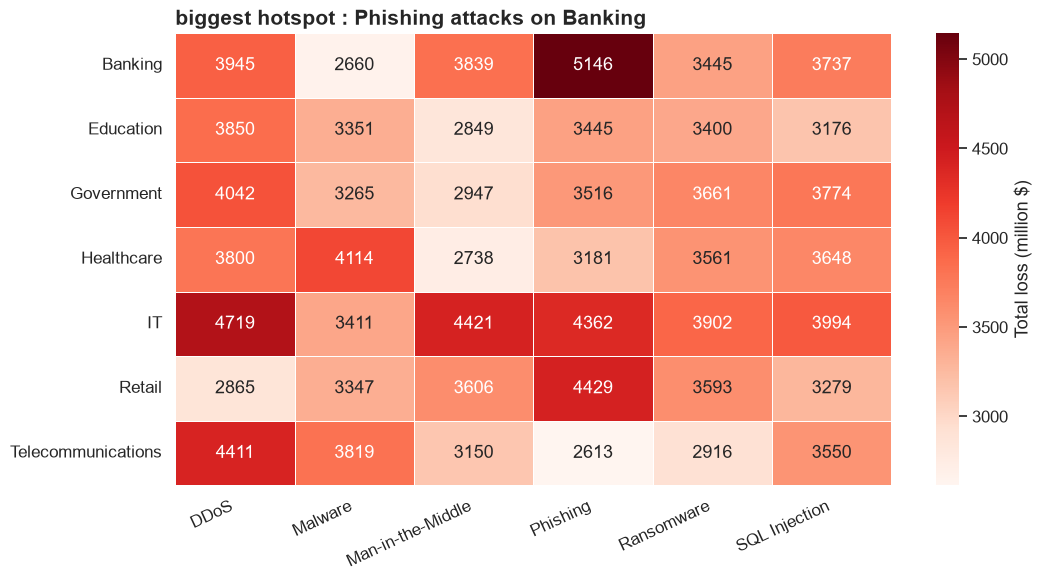

Hotspot: Phishing on Banking = 5,146 million $
Lowest: ('Telecommunications', 'Phishing') = 2,613 million $


In [11]:
pivot = df.pivot_table(index="industry",columns="attack_type",
                       values="loss_musd" , aggfunc="sum")
fig, ax = plt.subplots(figsize=(11,6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds",
            linewidths=0.5, cbar_kws={"label": "Total loss (million $)"}, ax=ax)
industry_top, attack_top = pivot.stack().idxmax()
top_value = pivot.stack().max()
ax.set_title(f"biggest hotspot : {attack_top} attacks on {industry_top}",
             loc = "left" , fontsize=15 , weight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.savefig("fig3_heatmap.png", dpi=300 , bbox_inches = "tight")
plt.show()

print(f"Hotspot: {attack_top} on {industry_top} = {top_value:,.0f} million $")
print("Lowest:", pivot.stack().idxmin(), f"= {pivot.stack().min():,.0f} million $")          

C:\Users\HP\AppData\Local\Temp\ipykernel_12456\1236439313.py:14: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


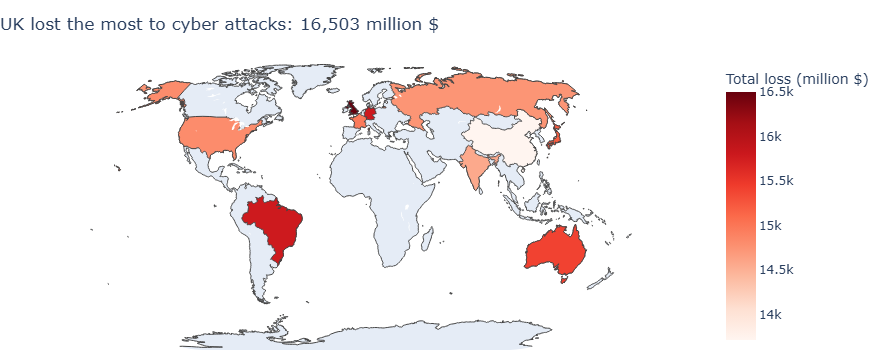

PNG export failed, take a screenshot of the map instead. 
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido



,country,incidents,total_loss,avg_loss,country_plot
8,UK,321,16503.0,51.4,United Kingdom
4,Germany,291,15793.2,54.3,Germany
1,Brazil,310,15782.6,50.9,Brazil
0,Australia,297,15403.0,51.9,Australia
6,Japan,305,15197.3,49.8,Japan
3,France,305,14972.3,49.1,France
9,USA,287,14812.1,51.6,United States
7,Russia,295,14734.7,49.9,Russia
5,India,308,14566.1,47.3,India
2,China,281,13714.5,48.8,China


In [12]:
country = (df.groupby("country")
             .agg(incidents=("year","size"),
                  total_loss=("loss_musd","sum"),
                  avg_loss=("loss_musd","mean"))
             .round(1)
             .reset_index())

# Plotly needs full country names
country["country_plot"] = country["country"].replace(
    {"UK": "United Kingdom", "USA": "United States"})

top = country.loc[country["total_loss"].idxmax()]

fig = px.choropleth(
    country,
    locations="country_plot",
    locationmode="country names",
    color="total_loss",
    hover_name="country",
    hover_data={"country_plot": False, "incidents": True, "avg_loss": True,
                "total_loss": ":,.0f"},
    color_continuous_scale="Reds",
    labels={"total_loss": "Total loss (million $)"},
    title=f"{top['country']} lost the most to cyber attacks: {top['total_loss']:,.0f} million $",
)
fig.update_layout(title_x=0, margin=dict(l=10, r=10, t=60, b=10),
                  geo=dict(showframe=False, showcoastlines=True,
                           projection_type="natural earth"))
fig.show()

fig.write_html("fig4_map.html")
try:
    fig.write_image("fig4_map.png", width=1100, height=600, scale=3)
except Exception as e:
    print("PNG export failed, take a screenshot of the map instead.", e)

country.sort_values("total_loss", ascending=False)

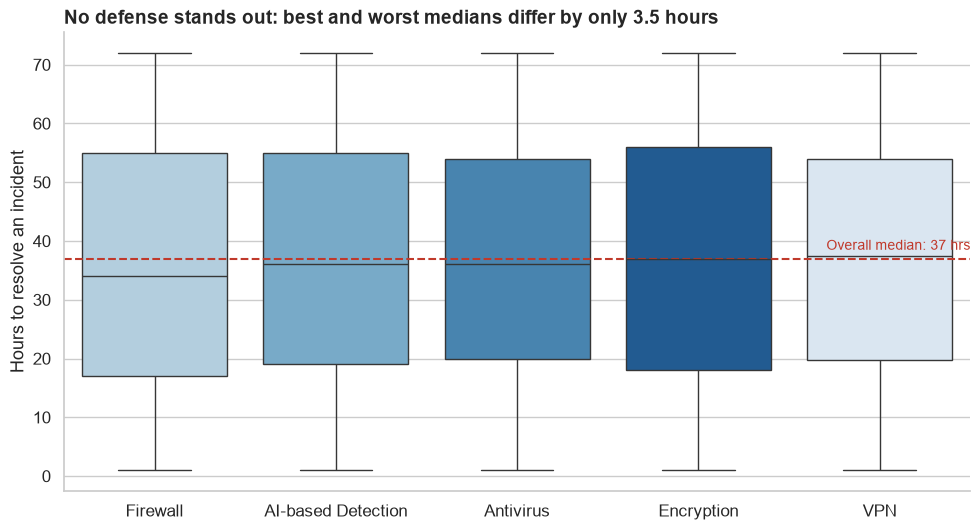

,count,mean,std,min,25%,50%,75%,max
defense,,,,,,,,
AI-based Detection,583.0,36.6,20.6,1.0,19.0,36.0,55.0,72.0
Antivirus,628.0,36.6,19.8,1.0,20.0,36.0,54.0,72.0
Encryption,592.0,36.6,21.2,1.0,18.0,37.0,56.0,72.0
Firewall,585.0,35.7,20.9,1.0,17.0,34.0,55.0,72.0
VPN,612.0,36.9,20.4,1.0,19.8,37.5,54.0,72.0


In [13]:
medians = df.groupby("defense")["resolution_hrs"].median()
order = medians.sort_values().index
gap = medians.max() - medians.min()
overall = df["resolution_hrs"].median()

fig, ax = plt.subplots(figsize=(10,5.5))
sns.boxplot(data=df, x="defense", y="resolution_hrs", order=order,
            hue="defense", palette="Blues", legend=False, ax=ax)

ax.axhline(overall, color="#c0392b", linestyle="--", lw=1.5)
ax.text(len(order) - 0.5, overall + 1.5, f"Overall median: {overall:.0f} hrs",
        color="#c0392b", ha="right", fontsize=10)

ax.set_title(f"No defense stands out: best and worst medians differ by only {gap:.1f} hours",
             loc="left", fontsize=14, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Hours to resolve an incident")
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.savefig("fig5_defense_box.png", dpi=300, bbox_inches="tight")
plt.show()

df.groupby("defense")["resolution_hrs"].describe().round(1)

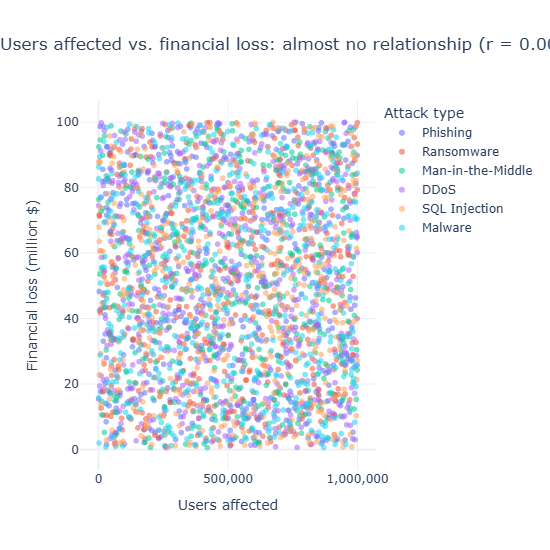

PNG export failed, use the camera icon on the chart instead. 
Image export using the "kaleido" engine requires the Kaleido package,
which can be installed using pip:

    $ pip install --upgrade kaleido



,loss_musd,user_affected,resolution_hrs
loss_musd,1.00,0.00,-0.01
user_affected,0.00,1.00,0.01
resolution_hrs,-0.01,0.01,1.00


In [14]:
r = df["user_affected"].corr(df["loss_musd"])
strength = "almost no" if abs(r) < 0.1 else ("a weak" if abs(r) < 0.3 else "a clear")

fig = px.scatter(
    df, x="user_affected", y="loss_musd", color="attack_type",
    opacity=0.55,
    hover_data=["country", "industry", "year", "resolution_hrs"],
    labels={"user_affected": "Users affected",
            "loss_musd": "Financial loss (million $)",
            "attack_type": "Attack type"},
    title=f"Users affected vs. financial loss: {strength} relationship (r = {r:.2f})",
)
fig.update_layout(title_x=0, template="plotly_white", height=550)
fig.update_xaxes(tickformat=",")
fig.show()

fig.write_html("fig6_scatter.html")
try:
    fig.write_image("fig6_scatter.png", width=1100, height=600, scale=3)
except Exception as e:
    print("PNG export failed, use the camera icon on the chart instead.", e)

df[["loss_musd", "user_affected", "resolution_hrs"]].corr().round(2)

In [15]:
print("Rows:", len(df), "| Years:", df["year"].min(), "-", df["year"].max())
print("Total loss (million $):", round(df["loss_musd"].sum()))
print("Correlation users vs loss:", round(df["user_affected"].corr(df["loss_musd"]), 3))
print("\nTop 3 countries by loss:\n", df.groupby("country")["loss_musd"].sum().round(0).sort_values(ascending=False).head(3))
print("\nBottom country:\n", df.groupby("country")["loss_musd"].sum().round(0).sort_values().head(1))
print("\nLoss by industry:\n", df.groupby("industry")["loss_musd"].sum().round(0).sort_values(ascending=False))
print("\nLoss by attack type:\n", df.groupby("attack_type")["loss_musd"].sum().round(0).sort_values(ascending=False))
print("\nAttack source counts:\n", df["source"].value_counts())

Rows: 3000 | Years: 2015 - 2024
Total loss (million $): 151479
Correlation users vs loss: 0.002

Top 3 countries by loss:
 country
UK         16503.0
Germany    15793.0
Brazil     15783.0
Name: loss_musd, dtype: float64

Bottom country:
 country
China    13714.0
Name: loss_musd, dtype: float64

Loss by industry:
 industry
IT                    24810.0
Banking               22772.0
Government            21205.0
Retail                21120.0
Healthcare            21041.0
Telecommunications    20459.0
Education             20071.0
Name: loss_musd, dtype: float64

Loss by attack type:
 attack_type
DDoS                 27631.0
Phishing             26693.0
SQL Injection        25157.0
Ransomware           24479.0
Malware              23968.0
Man-in-the-Middle    23551.0
Name: loss_musd, dtype: float64

Attack source counts:
 source
Nation-state    794
Unknown         768
Insider         752
Hacker Group    686
Name: count, dtype: int64


ModuleNotFoundError: No module named 'docx'